We perform some basic experiments by fitting a cirle. 

In [1]:
# First manage the imports
import numpy as np

from bliss.inference.likelihoods import MarginalLikelihood
from bliss.inference.posterior import MarginalPosterior
from bliss.inference.samplers.map_estimation import MAPOptimizer
from bliss.visualization.plotting_2d import ShapePlotter2D
from bliss.inference.noise_functions import IsotropicNoise
from bliss.inference.source_densitites import UniformSourceDensity, MixtureSourceDensity
from bliss.models.shapes.shape_examples import shape_cases
from bliss.utils.sample_data import simulate_measurement

Importing bayes_shape_fitting.inference
Importing bayes_shape_fitting.models.shapes
Importing bayes_shape_fitting.visualization
Importing bayes_shape_fitting.utils


In [2]:
# first we define the shape case
case = shape_cases[0]

shape = case["shape"]
theta = case["theta"]
init_theta = case["init_params"]

In [3]:
# we define a uniform source density
source_density_true = UniformSourceDensity(n_dim = 1, fixed_params=np.array([0.4,0.1]), domain_low=shape.domain_low, domain_high=shape.domain_high, periodic=shape.periodic)

In [4]:
# the noise function is chosen to be isotropic
noise_function = IsotropicNoise(dim_param=shape.parameter_dim, dim_ambient=shape.ambient_dim, fixed_params=0.1)

In [5]:
# simulate a measurement of 100 points
measurement = simulate_measurement(shape, theta, source_density_true, noise_function, num_samples=100)

In [6]:
# for formulating a posterior, we need to define likelihood and prior
# we choose a Gaussian Mixture as source density

source_density = MixtureSourceDensity(n_components = 1, prior = None)

In [7]:
# then the likelihood 
likelihood = MarginalLikelihood(shape=shape, source_density=source_density, noise_function=noise_function, num_samples = 50)

In [8]:
# and the posterior
posterior = MarginalPosterior(shape=shape, measurement=measurement, likelihood=likelihood)

In [9]:
# now we define the optimizer
optimizer = MAPOptimizer(method='L-BFGS-B', verbose=True)

In [10]:
# let us define an initial guess for the Gaussian Mixture
init_source_density = np.array([0.3, 0.2, 0.0])     # mu1, sigma1, logit1  

(<Figure size 1000x800 with 1 Axes>,
 <Axes: title={'center': 'Source Density Function'}, xlabel='Parameter t', ylabel='Density'>)

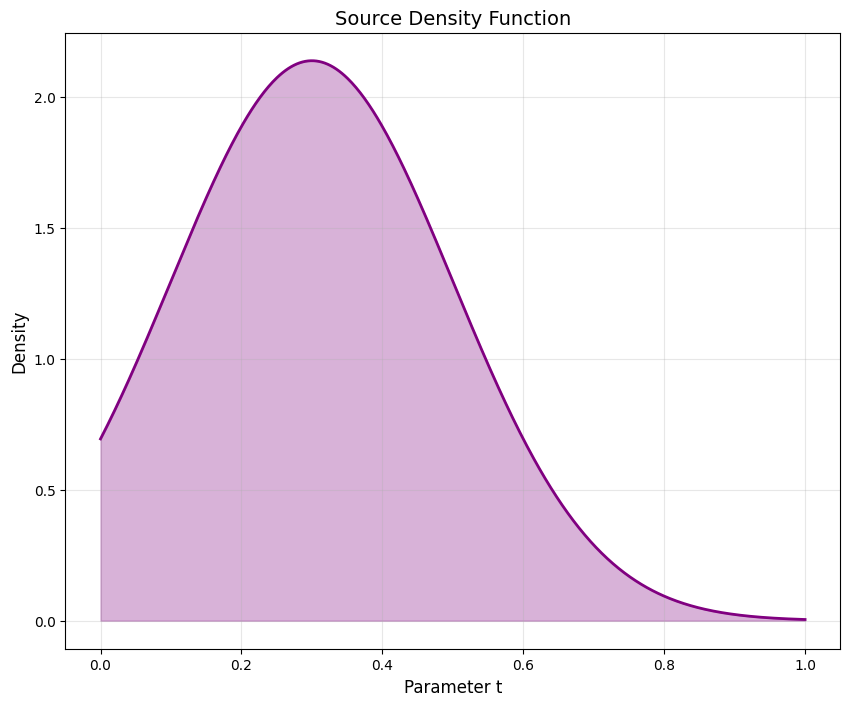

In [11]:
# Let's define a plotter and plot the initial source_density
plotter = ShapePlotter2D()
plotter.plot_source_density(shape, source_density, params=init_source_density)

In [12]:
# perform the MAP estimation
bounds = source_density.n_components * [(0,1),(0.01,np.inf),(None,None)]
result = optimizer.optimize(posterior, shape_init = init_theta, source_init=init_source_density, source_bounds=bounds)

MAP Optimization with L-BFGS-B
Initial log posterior: -238.668176
Optimizing blocks: shape source
Number of optimized parameters: 6
Using box constraints: 6 bounds


Optimization Complete
Success: True
Message: CONVERGENCE: RELATIVE REDUCTION OF F <= FACTR*EPSMCH
Final log posterior: -151.911653
Improvement: 86.756523
Iterations: 18
Function evaluations: 189
Runtime: 0.145s
----------------------------------------------------------------------
⚠ Abnormal termination detected
• First-order optimality not satisfied: ||g||_inf=2.850e-01 > tol=1.000e-04
Gradient infinity-norm: 2.850e-01



In [13]:
theta_map = result.theta_map[0:3]

(<Figure size 1000x800 with 1 Axes>, <Axes: >)

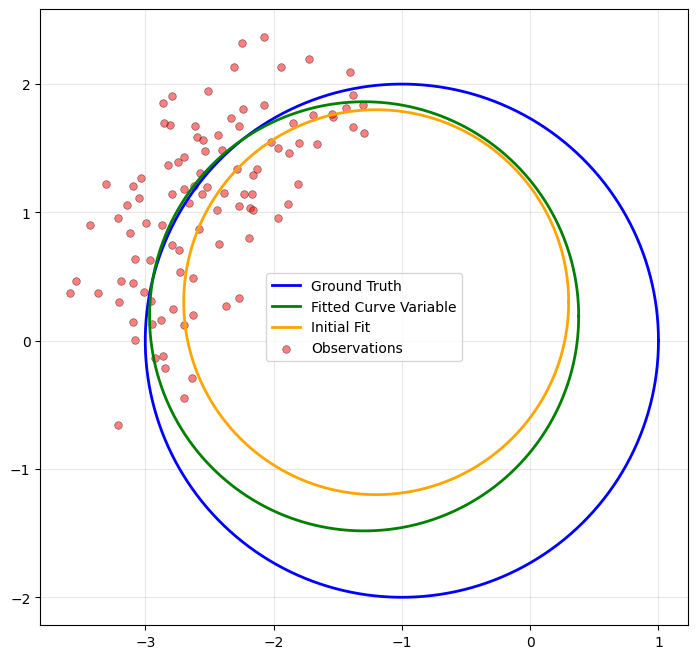

In [14]:
# we plot the result of the fit
fig, ax, _ = plotter.plot_shape(shape, theta, label="Ground Truth")
plotter.plot_shape(shape, theta_map, ax=ax, label="Fitted Curve Variable", color="green")
plotter.plot_shape(shape, init_theta, ax=ax, label="Initial Fit", color="orange")
plotter.plot_observations(observations=measurement, ax=ax)

(<Figure size 1000x800 with 1 Axes>,
 <Axes: title={'center': 'Source Density Function'}, xlabel='Parameter t', ylabel='Density'>)

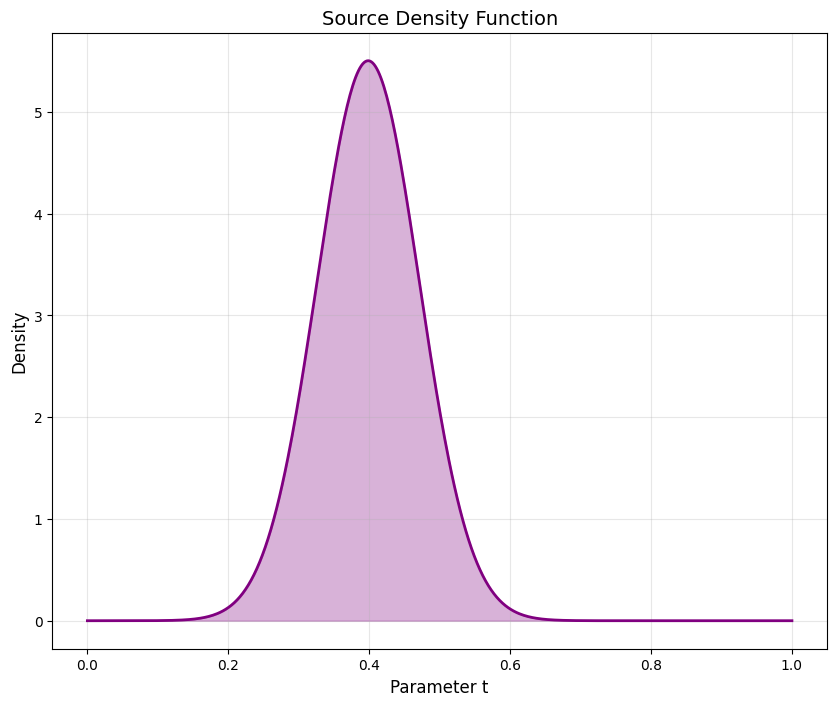

In [15]:
# also plot the final source density
source_map = result.theta_map[3:]
plotter.plot_source_density(shape, source_density, params=source_map)